# Reproduction of the mitoMammal glucose oxidation simulation

This notebook reproduces the aerobic glucose oxidation simulation of Chapman et al. (2025), which was used to validate mitoMammal's ability to simulate mitochondrial energy metabolism. In the original simulation, the objective function was maximisation of cytosolic ATP hydrolysis (`OF_ATP_mitoMap`), and all nutrient input reactions were constrained to zero except those for glucose and oxygen. Under these conditions, the authors reported a yield of 31 ATP per glucose, consistent with theoretical estimates of 30–32 ATP.

**Model:** `6_universal_mito_model.xml` (SBML Level 3 Version 1), from the Habermann Lab GitLab repository (https://gitlab.com/habermann_lab/mitomammal/).

**Software:** Python 3.8.20, COBRApy 0.29.0, GLPK (swiglpk 5.0.13), NumPy 1.24.3, pandas 2.0.3, Matplotlib 3.7.2 and python-libsbml 5.21.1, in a conda environment configured according to the authors' README.

**Conventions:**
- Exchange reactions are written in the direction of secretion: negative flux = uptake, positive flux = secretion.
- Glucose uptake is fixed at 1, so all fluxes are expressed in mol per mol glucose.
- A bound of ±1000 represents an effectively unbounded flux.

**Structure:**
- **Section 1: Default model.** Inspection of the glucose and oxygen exchange and transport reactions, and the flux distribution, under default bounds.
- **Section 2: Glucose oxidation test.** Application of the simulation constraints (thesis Table 3.2) and prediction of the flux distribution with pFBA.
- **Section 3: Verification and analysis.** Verifying key fluxes, exchanges and transporters, and PMF costs and contributions (thesis Figure 4.1 and Table 4.1).

In [1]:
import cobra
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from collections import defaultdict

# Confirm the solver is working:
print(cobra.Configuration().solver)

model_path=r"C:\Users\cayle\OneDrive\Documents\Master's Reserach\MitoMammal Data\MitoMammal Coding Books\6_universal_mito_model.xml"
MitoMammal_model= cobra.io.read_sbml_model(model_path)

<module 'optlang.glpk_interface' from 'c:\\Users\\cayle\\miniconda3\\envs\\mitomammal\\lib\\site-packages\\optlang\\glpk_interface.py'>


In [2]:
# Saving a JSON copy of the model, for optional visualisation in Escherr
cobra.io.save_json_model(MitoMammal_model, "mitomammal.json")

In [3]:
# Printing the current working directory (where output files such as the JSON and Excel files will be saved)

import os
print(os.getcwd())

c:\Users\cayle\OneDrive\Documents\Master's Reserach\MitoMammal Data\MitoMammal Coding Books


In [4]:
# Checking model compartments to aid in understanding of model structure, prefixes and suffixes. 
print(MitoMammal_model.compartments)

{'Cytosol': 'Cytosol', 'Mitochondrion': 'Mitochondrion', 'external': 'External'}


# Section 1

## Default Model flux bounds

Investigation of oxygen and glucose uptake and transport reactions and their model defualt flux distributions, prior to applying constraints for the simualtion of the complete oxidation of one glucose molecule. 



oxygen

In [5]:
ex_o2 = MitoMammal_model.reactions.get_by_id("EX_o2_e")

#Print summary
print("=" * 70)
print(f"Reaction ID:      {ex_o2.id}")
print(f"Name:             {ex_o2.name}")
print(f"Lower bound:      {ex_o2.lower_bound}")
print(f"Upper bound:      {ex_o2.upper_bound}")
print(f"Reaction equation: {ex_o2.reaction}")
print(f"Gene association:  {ex_o2.gene_reaction_rule}")
print(f"Subsystem:         {ex_o2.subsystem}")
print("=" * 70)

#Show stoichiometry
print("\nStoichiometry details:")
for met, coeff in ex_o2.metabolites.items():
    print(f"  {coeff:+.1f} {met.id} ({met.name})")

Reaction ID:      EX_o2_e
Name:             EX_o2_e
Lower bound:      -1000.0
Upper bound:      1000.0
Reaction equation: o2_e <=> 
Gene association:  
Subsystem:         

Stoichiometry details:
  -1.0 o2_e (Oxygen)


In [6]:
O2 = MitoMammal_model.reactions.get_by_id("O2t")

#Print summary
print("=" * 70)
print(f"Reaction ID:      {O2.id}")
print(f"Name:             {O2.name}")
print(f"Lower bound:      {O2.lower_bound}")
print(f"Upper bound:      {O2.upper_bound}")
print(f"Reaction equation: {O2.reaction}")
print(f"Gene association:  {O2.gene_reaction_rule}")
print(f"Subsystem:         {O2.subsystem}")
print("=" * 70)

#Stoichiometry
print("\nStoichiometry details:")
for met, coeff in O2.metabolites.items():
    print(f"  {coeff:+.1f} {met.id} ({met.name})")

Reaction ID:      O2t
Name:             R_O2t o2 transport (diffusion)
Lower bound:      0.0
Upper bound:      19.8
Reaction equation: o2_e --> o2_c
Gene association:  
Subsystem:         Boundary conditions - core

Stoichiometry details:
  -1.0 o2_e (Oxygen)
  +1.0 o2_c (Oxygen)


In [7]:
oxygen = MitoMammal_model.metabolites.o2_c
print(oxygen.summary().to_string())

o2_c
====
Formula: O2

Producing Reactions
-------------------
Percent Flux Reaction    Definition
100.00% 19.8      O2t o2_e --> o2_c

Consuming Reactions
-------------------
Percent  Flux Reaction    Definition
100.00% -19.8     O2tm o2_c <=> o2_m


____________________________________________________________________________________

glucose


In [8]:

glct = MitoMammal_model.reactions.get_by_id("GLCt1r")

print("=" * 70)
print(f"Reaction ID:      {glct.id}")
print(f"Name:             {glct.name}")
print(f"Lower bound:      {glct.lower_bound}")
print(f"Upper bound:      {glct.upper_bound}")
print(f"Reaction equation: {glct.reaction}")
print(f"Gene association:  {glct.gene_reaction_rule}")
print(f"Subsystem:         {glct.subsystem}")
print("=" * 70)

print("\nStoichiometry details:")
for met, coeff in glct.metabolites.items():
    print(f"  {coeff:+.1f} {met.id} ({met.name})")

Reaction ID:      GLCt1r
Name:             R_GLCt1r glucose transport
Lower bound:      -1000.0
Upper bound:      0.9
Reaction equation: glc_D_e <=> glc_D_c
Gene association:  
Subsystem:         Boundary conditions - core

Stoichiometry details:
  -1.0 glc_D_e (D-Glucose)
  +1.0 glc_D_c (D-Glucose)


In [9]:
ex_glc = MitoMammal_model.reactions.get_by_id("EX_glc_D_e")

print("=" * 70)
print(f"Reaction ID:      {ex_glc.id}")
print(f"Name:             {ex_glc.name}")
print(f"Lower bound:      {ex_glc.lower_bound}")
print(f"Upper bound:      {ex_glc.upper_bound}")
print(f"Reaction equation: {ex_glc.reaction}")
print(f"Gene association:  {ex_glc.gene_reaction_rule}")
print(f"Subsystem:         {ex_glc.subsystem}")
print("=" * 70)

print("\nStoichiometry details:")
for met, coeff in ex_glc.metabolites.items():
    print(f"  {coeff:+.1f} {met.id} ({met.name})")

Reaction ID:      EX_glc_D_e
Name:             EX_glc_D_e
Lower bound:      -1000.0
Upper bound:      1000.0
Reaction equation: glc_D_e <=> 
Gene association:  
Subsystem:         

Stoichiometry details:
  -1.0 glc_D_e (D-Glucose)


In [10]:
glucose = MitoMammal_model.metabolites.glc_D_c
print(glucose.summary().to_string())

glc_D_c
Formula: C6H12O6

Producing Reactions
-------------------
Percent Flux Reaction          Definition
100.00%  0.9   GLCt1r glc_D_e <=> glc_D_c

Consuming Reactions
-------------------
Percent Flux Reaction                              Definition
100.00% -0.9     HEX1 atp_c + glc_D_c --> adp_c + g6p_c + h_c


_____________________________________________________________________________________

ATP


In [11]:
met = MitoMammal_model.metabolites.atp_c
print(met.summary().to_string())

atp_c
=====
Formula: C10H12N5O13P3

Producing Reactions
-------------------
Percent  Flux       Reaction                                                Definition
 96.41% 99.93 ATPtmB_mitoMap 0.82 PMF_c + adp_c + atp_m <=> 0.82 PMF_m + adp_m + atp_c
  1.75%  1.81            PGK                         3pg_c + atp_c <=> 13dpg_c + adp_c
  1.84% 1.906            PYK                     adp_c + h_c + pep_c --> atp_c + pyr_c

Consuming Reactions
-------------------
Percent    Flux       Reaction                                          Definition
  0.45% -0.4697           ADK1                         amp_c + atp_c <=> 2.0 adp_c
  0.45% -0.4697     FACOAL160i atp_c + coa_c + hdca_c --> amp_c + pmtcoa_c + ppi_c
  0.01%   -0.01           GLYK           atp_c + glyc_c --> adp_c + glyc3p_c + h_c
  0.87%    -0.9           HEX1             atp_c + glc_D_c --> adp_c + g6p_c + h_c
 97.35%  -100.9 OF_ATP_mitoMap    atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c
  0.87%    -0.9            PFK       

_____________________________________________________________________________________

Exchange reactions: 

In [12]:
for rxn in MitoMammal_model.reactions:
    if "exchange" in rxn.name.lower() or rxn.id.startswith("EX"):
        print(rxn.id, rxn.name)


EX_2hb_e EX_2hb_e
EX_ac_e EX_ac_e
EX_acac_e EX_acac_e
EX_akg_e EX_akg_e
EX_ala_B_e EX_ala_B_e
EX_ala_L_e EX_ala_L_e
EX_arg_L_e EX_arg_L_e
EX_argsuc_e EX_argsuc_e
EX_asn_L_e EX_asn_L_e
EX_asp_L_e EX_asp_L_e
EX_bhb_e EX_bhb_e
EX_bilirub_e EX_bilirub_e
EX_biomass_e EX_biomass_e
EX_but_e EX_but_e
EX_chol_e EX_chol_e
EX_cit_e EX_cit_e
EX_citr_L_e EX_citr_L_e
EX_co_e EX_co_e
EX_co2_e EX_co2_e
EX_creat_e EX_creat_e
EX_cyan_e EX_cyan_e
EX_cys_L_e EX_cys_L_e
EX_etoh_e EX_etoh_e
EX_fe2_e EX_fe2_e
EX_for_e EX_for_e
EX_fum_e EX_fum_e
EX_glc_D_e EX_glc_D_e
EX_gln_L_e EX_gln_L_e
EX_glu_L_e EX_glu_L_e
EX_gly_e EX_gly_e
EX_glyc_e EX_glyc_e
EX_h_e EX_h_e
EX_h2o_e EX_h2o_e
EX_HC00250_e EX_HC00250_e
EX_hco3_e EX_hco3_e
EX_hdca_e EX_hdca_e
EX_his_L_e EX_his_L_e
EX_icit_e EX_icit_e
EX_ile_L_e EX_ile_L_e
EX_lac_L_e EX_lac_L_e
EX_leu_L_e EX_leu_L_e
EX_lys_L_e EX_lys_L_e
EX_mal_L_e EX_mal_L_e
EX_mercplac_e EX_mercplac_e
EX_met_L_e EX_met_L_e
EX_nad_e EX_nad_e
EX_nadh_e EX_nadh_e
EX_nh4_e EX_nh4_e
EX_no_e EX_n

### Export Section 1 results to Excel

In [13]:
import pandas as pd
from openpyxl.styles import Font

#turns reaction details (the same as the print cells above) into a table
def reaction_details(model, reaction_ids):
    rows = []
    for rid in reaction_ids:
        r = model.reactions.get_by_id(rid)
        stoich = "; ".join(f"{coeff:+.1f} {met.id} ({met.name})"
                           for met, coeff in r.metabolites.items())
        rows.append({
            "Reaction ID": r.id,
            "Name": r.name,
            "Lower bound": r.lower_bound,
            "Upper bound": r.upper_bound,
            "Reaction equation": r.reaction,
            "Stoichiometry": stoich,
            "Gene association": r.gene_reaction_rule,
            "Subsystem": r.subsystem,
        })
    return pd.DataFrame(rows)

#turns a metabolite .summary() into a table (zero fluxes removed, full decimals kept).
#with no solution given, .summary() works exactly as in the cells above.
def metabolite_summary_table(model, met_id, solution=None):
    summ = model.metabolites.get_by_id(met_id).summary(solution=solution)
    tables = []
    for direction, df in [("Producing", summ.producing_flux),
                          ("Consuming", summ.consuming_flux)]:
        df = df[df["flux"].abs() > model.tolerance].copy()
        df.insert(0, "Direction", direction)
        df["percent"] = df["percent"] * 100
        df["Definition"] = [model.reactions.get_by_id(r).reaction for r in df["reaction"]]
        tables.append(df)
    out = pd.concat(tables)
    out = out.rename(columns={"reaction": "Reaction ID", "flux": "Flux",
                              "percent": "Percent (%)"})
    return out[["Direction", "Reaction ID", "Flux", "Percent (%)", "Definition"]]


def write_sheet(writer, sheet_name, title, blocks):
    row = 2
    heading_rows = []
    for heading, df in blocks:
        heading_rows.append(row)
        df.to_excel(writer, sheet_name=sheet_name, startrow=row + 1, index=False)
        row += len(df) + 4
    ws = writer.sheets[sheet_name]
    ws["A1"] = title
    ws["A1"].font = Font(bold=True, size=11)
    for (heading, df), r in zip(blocks, heading_rows):
        ws.cell(row=r + 1, column=1, value=heading).font = Font(bold=True, size=11)
    for col_cells in ws.columns:
        longest = max(len(str(c.value)) if c.value is not None else 0 for c in col_cells[1:])
        ws.column_dimensions[col_cells[0].column_letter].width = min(max(longest + 2, 10), 70)

In [14]:
#Section 1 export to excel: default model (before any constraints)

#load a fresh, unmodified copy of the model from the .xml file, so these results always reflect the default bounds, whatever cells have been run
default_model = cobra.io.read_sbml_model(model_path)

#model information
default_model_info = pd.DataFrame({
    "Item": ["Model file", "Solver", "Working directory",
             "Number of reactions", "Number of metabolites", "Number of genes",
             "Objective"],
    "Value": [model_path,
              cobra.Configuration().solver.__name__,
              os.getcwd(),
              len(default_model.reactions),
              len(default_model.metabolites),
              len(default_model.genes),
              str(default_model.objective.expression)],
})
default_compartments = pd.DataFrame({
    "Compartment ID": list(default_model.compartments.keys()),
    "Compartment name": list(default_model.compartments.values()),
})

#oxygen
default_o2_reactions = reaction_details(default_model, ["EX_o2_e", "O2t"])
default_o2_c_summary = metabolite_summary_table(default_model, "o2_c")

#glucose 
default_glc_reactions = reaction_details(default_model, ["GLCt1r", "EX_glc_D_e"])
default_glc_D_c_summary = metabolite_summary_table(default_model, "glc_D_c")

#ATP 
default_atp_c_summary = metabolite_summary_table(default_model, "atp_c")

#exchange reactions (same filter as the exchange cell above) 
default_exchange_ids = [rxn.id for rxn in default_model.reactions
                        if "exchange" in rxn.name.lower() or rxn.id.startswith("EX")]
default_exchanges = reaction_details(default_model, default_exchange_ids)[
    ["Reaction ID", "Name", "Lower bound", "Upper bound", "Reaction equation"]]

#write one excel workbook with five sheets 
section1_file = "Section1_Default_Model Constraints_ Glucose_Ox.xlsx"

with pd.ExcelWriter(section1_file, engine="openpyxl") as writer:
    write_sheet(writer, "Model info", "Model information", [
        ("Model", default_model_info),
        ("Compartments", default_compartments),
    ])
    write_sheet(writer, "Oxygen", "Oxygen uptake and transport (default bounds)", [
        ("Reaction details", default_o2_reactions),
        ("Metabolite summary: o2_c", default_o2_c_summary),
    ])
    write_sheet(writer, "Glucose", "Glucose uptake and transport (default bounds)", [
        ("Reaction details", default_glc_reactions),
        ("Metabolite summary: glc_D_c", default_glc_D_c_summary),
    ])
    write_sheet(writer, "ATP", "Cytosolic ATP (default bounds)", [
        ("Metabolite summary: atp_c", default_atp_c_summary),
    ])
    write_sheet(writer, "Exchange reactions", "Exchange reactions (default bounds)", [
        (f"All exchange reactions (n = {len(default_exchanges)})", default_exchanges),
    ])

print("Saved to:", os.path.abspath(section1_file))

Saved to: c:\Users\cayle\OneDrive\Documents\Master's Reserach\MitoMammal Data\MitoMammal Coding Books\Section1_Default_Model Constraints_ Glucose_Ox.xlsx


___________________________________________________________________________________________________________________________________________________________

_______________________________________________________________________________________________________________________________________________________

## Section 2
### Complete oxidation of one glucose molecule under aerobic conditions 

The model is constrained according to the conditions specified by the authors: all nutrient input reactions are constrained to zero, except for oxygen and glucose Chapman et al. (2025).

" MitoMammal is based on MitoCore, a human specific cardiomyocyte mitochondrial model.
MitoMammal was first tested on its ability to correctly produce accurate ATP levels from glucose
oxidation. All nutrient input reactions except glucose and oxygen were constrained to zero to
reflect aerobic glycolytic conditions. Maximisation of ATP hydrolysis was used as the objective
function for these simulations and the model was then optimised using parsimonious FBA for all
simulations reported in this work. As expected, MitoMammal correctly predicted the production of
31 molecules of ATP from 1 molecule of glucose (Supplementary Figure S1)." 

**Constraints applied:**

| Reaction | Default bounds | Test bounds | Reason |
|---|---|---|---|
| All exchange reactions (`EX_`) | various | (0, 1000) | No uptake; secretion permitted |
| `EX_glc_D_e` | (−1000, 1000) | (−1, −1) | Uptake fixed at exactly 1 glucose |
| `EX_o2_e` | (−1000, 1000) | (−1000, 1000) | Reset after the step above; oxygen not limiting |
| `GLCt1r` | (−1000, 0.9) | (−1000, 1000) | Default upper flux of 0.9 would block uptake of 1 glucose |
| `O2t` | (0, 19.8) | unchanged | The 19.8 of oxygen exceeds the required ~6 O₂ for the oxidation of one glucose|

The objective, maximisation of `OF_ATP_mitoMap` (cytosolic ATP hydrolysis), was unchanged. The flux distribution was predicted with pFBA.

**Key outputs (molecule per molecule glucose):**
- **Total ATP yield:** `OF_ATP_mitoMap` = 32.773
  - **Glycolysis:** net 1.998 ATP
  - **Mitochondrial respiration:** 30.785 ATP, exported by the ADP/ATP carrier (`ATPtmB_mitoMap`)
    - ATP synthase (`CV_mitoMap`): 28.806
    - Succinyl-CoA synthetase (`SUCOASm`): 1.979
  - **ATP-citrate lyase (`ACITL`):** −0.010
- **O₂ consumed:** 5.951 (5.941 reduced by complex IV)
- **Secreted:** CO₂ 5.951, H₂O 5.951, lactate 0.010, acetate 0.010

The mitochondrial contribution (30.785) closely matches the 31 ATP reported by the authors. The total of 32.773 also includes net glycolytic ATP. These results are discussed in thesis Section 4.1.1 (Figure 4.1, Table 4.1).



In [15]:
#preparing to run pfba 
from cobra.flux_analysis import pfba

Changing the constraints on the flux bounds from the model defualt

In [16]:
#lower bound 0, for no nurtient uptake. 
#upper bound 1000 for secretion of metabolites. 
for rxn in MitoMammal_model.exchanges:
    rxn.lower_bound= 0
    rxn.upper_bound= 1000

input_glc_exchange= MitoMammal_model.reactions.get_by_id('EX_glc_D_e')
input_o2_exchange= MitoMammal_model.reactions.get_by_id('EX_o2_e')
   

In [17]:
#attempts at constraining glucose uptake to 1 moelcule 
input_glc_exchange.lower_bound= -1
input_glc_exchange.upper_bound= -1

#excess oxygen, so that it does not become a limiting factor 
input_o2_exchange.lower_bound= -1000
input_o2_exchange.upper_bound= 1000

In [18]:
#Changing the upper flux bound of the GLCt1r glucose transporter reaction
#So that glucose uptake into mitochondria is not fixed at 0.9
glct = MitoMammal_model.reactions.get_by_id("GLCt1r")
glct.upper_bound = 1000
print(glct.bounds)

#confirming the flux bounds for glucose uptake and secretion 
glc = MitoMammal_model.reactions.get_by_id("EX_glc_D_e")
print(glc.bounds)

(-1000.0, 1000)
(-1, -1)


In [19]:
#confirming the objective function 
print(MitoMammal_model.objective)

Maximize
1.0*OF_ATP_mitoMap - 1.0*OF_ATP_mitoMap_reverse_44b94


In [20]:
atptmb = MitoMammal_model.reactions.get_by_id("ATPtmB_mitoMap")
print(atptmb.name)
print(atptmb.reaction)
print(atptmb.bounds)
print(atptmb.subsystem)

R_ATPtmB_mitoMap ADP/ATP carrier - antiport ATP for ADP
0.82 PMF_c + adp_c + atp_m <=> 0.82 PMF_m + adp_m + atp_c
(-1000.0, 1000.0)
Mitochondrial transporters - characterised


In [21]:
solution = pfba(MitoMammal_model)
print(solution.fluxes["OF_ATP_mitoMap"])

32.77312578750859


In [22]:
#solution = MitoMammal_model.optimize()
#print(solution)

_______________________________________________________________________________________________________________________________________________________

### pFBA Results after Change on Constraints

In [23]:
rxns = ["EX_glc_D_e", "GLCt1r", "EX_o2_e", "O2t", "O2tm",
        "ATPtmB_mitoMap", "OF_ATP_mitoMap"]
print(solution.fluxes[rxns])

EX_glc_D_e        -1.000000
GLCt1r             1.000000
EX_o2_e           -5.950524
O2t                5.950524
O2tm               5.950524
ATPtmB_mitoMap    30.784792
OF_ATP_mitoMap    32.773126
Name: fluxes, dtype: float64


In [24]:
ex = solution.fluxes[[r.id for r in MitoMammal_model.exchanges]]
print(ex[ex.abs() > 1e-6])

EX_ac_e          0.010000
EX_biomass_e    32.773126
EX_co2_e         5.950524
EX_glc_D_e      -1.000000
EX_h2o_e         5.950524
EX_lac_L_e       0.009825
EX_o2_e         -5.950524
Name: fluxes, dtype: float64


In [25]:
#met_biomass = MitoMammal_model.metabolites.biomass_c
#print(met_biomass.summary().to_string())

met_biomass = MitoMammal_model.metabolites.biomass_c
print(met_biomass.summary(solution=solution).to_string())  

biomass_c
Formula: BIOMASS

Producing Reactions
-------------------
Percent  Flux       Reaction                                       Definition
100.00% 32.77 OF_ATP_mitoMap atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c

Consuming Reactions
-------------------
Percent   Flux        Reaction              Definition
100.00% -32.77 Biomass_mitoMap biomass_e <-- biomass_c


oxygen

In [26]:
met_o2 = MitoMammal_model.metabolites.o2_c                   # in the cytosol
print(met_o2.summary(solution=solution).to_string())    


met_o2m = MitoMammal_model.metabolites.o2_m                  # in the mitochondria
print(met_o2m.summary(solution=solution).to_string())   


o2_c
====
Formula: O2

Producing Reactions
-------------------
Percent  Flux Reaction    Definition
100.00% 5.951      O2t o2_e --> o2_c

Consuming Reactions
-------------------
Percent   Flux Reaction    Definition
100.00% -5.951     O2tm o2_c <=> o2_m
o2_m
====
Formula: O2

Producing Reactions
-------------------
Percent     Flux Reaction                            Definition
 99.83%    5.951     O2tm                         o2_c <=> o2_m
  0.17% 0.009913   SPODMm 2.0 h_m + 2.0 o2s_m --> h2o2_m + o2_m

Consuming Reactions
-------------------
Percent     Flux    Reaction                                                                      Definition
 99.67%   -5.941 CIV_mitoMap        8.0 PMF_m + 4.0 focytC_m + o2_m --> 4.0 PMF_c + 4.0 ficytC_m + 2.0 h2o_m
  0.33% -0.01983  CI_mitoMap 3.996 PMF_m + h_m + nadh_m + 0.002 o2_m + 0.999 q10_m <=> 3.996 PMF_c + nad_...


glucose

In [27]:
#gluc= MitoMammal_model.metabolites.glc_D_c
#print(gluc.summary().to_string())

gluc = MitoMammal_model.metabolites.glc_D_c            # in the cytosol
print(gluc.summary(solution=solution).to_string())   

glc_D_c
Formula: C6H12O6

Producing Reactions
-------------------
Percent Flux Reaction          Definition
100.00%    1   GLCt1r glc_D_e <=> glc_D_c

Consuming Reactions
-------------------
Percent Flux Reaction                              Definition
100.00%   -1     HEX1 atp_c + glc_D_c --> adp_c + g6p_c + h_c


ATP/ADP

In [28]:
#met = MitoMammal_model.metabolites.atp_c
#print(met.summary().to_string())


met_atpc = MitoMammal_model.metabolites.atp_c              # in the cytosol
print(met_atpc.summary(solution=solution).to_string()) 


met_atpm = MitoMammal_model.metabolites.atp_m              # in the mitochondria
print(met_atpm.summary(solution=solution).to_string()) 


atp_c
=====
Formula: C10H12N5O13P3

Producing Reactions
-------------------
Percent  Flux       Reaction                                                Definition
 88.51% 30.78 ATPtmB_mitoMap 0.82 PMF_c + adp_c + atp_m <=> 0.82 PMF_m + adp_m + atp_c
  5.75% 1.998            PGK                         3pg_c + atp_c <=> 13dpg_c + adp_c
  5.75% 1.998            PYK                     adp_c + h_c + pep_c --> atp_c + pyr_c

Consuming Reactions
-------------------
Percent    Flux       Reaction                                               Definition
  0.03%   -0.01          ACITL atp_c + cit_c + coa_c --> accoa_c + adp_c + oaa_c + pi_c
  2.88%      -1           HEX1                  atp_c + glc_D_c --> adp_c + g6p_c + h_c
 94.23%  -32.77 OF_ATP_mitoMap         atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c
  2.87% -0.9983            PFK                    atp_c + f6p_c --> adp_c + fdp_c + h_c
atp_m
=====
Formula: C10H12N5O13P3

Producing Reactions
-------------------
Percent  Flux   Rea

In [29]:
#met_adp = MitoMammal_model.metabolites.adp_c
#print(met_adp.summary().to_string())

met_adp = MitoMammal_model.metabolites.adp_c            # in the cytosol
print(met_adp.summary(solution=solution).to_string())   

adp_c
=====
Formula: C10H12N5O10P2

Producing Reactions
-------------------
Percent   Flux       Reaction                                               Definition
  0.03%   0.01          ACITL atp_c + cit_c + coa_c --> accoa_c + adp_c + oaa_c + pi_c
  2.88%      1           HEX1                  atp_c + glc_D_c --> adp_c + g6p_c + h_c
 94.23%  32.77 OF_ATP_mitoMap         atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c
  2.87% 0.9983            PFK                    atp_c + f6p_c --> adp_c + fdp_c + h_c

Consuming Reactions
-------------------
Percent   Flux       Reaction                                                Definition
 88.51% -30.78 ATPtmB_mitoMap 0.82 PMF_c + adp_c + atp_m <=> 0.82 PMF_m + adp_m + atp_c
  5.75% -1.998            PGK                         3pg_c + atp_c <=> 13dpg_c + adp_c
  5.75% -1.998            PYK                     adp_c + h_c + pep_c --> atp_c + pyr_c


NAD/NADH

In [30]:
#met_nadc = MitoMammal_model.metabolites.nad_c
#print(met_nadc.summary().to_string())

met_nadc = MitoMammal_model.metabolites.nad_c            # in the cytosol
print(met_nadc.summary(solution=solution).to_string())  

met_nadm = MitoMammal_model.metabolites.nad_m            # in the mitochondria
print(met_nadm.summary(solution=solution).to_string())

nad_c
=====
Formula: C21H26N7O14P2

Producing Reactions
-------------------
Percent     Flux Reaction                               Definition
  0.49% 0.009825    LDH_L lac_L_c + nad_c <=> h_c + nadh_c + pyr_c
 99.51%    1.989      MDH mal_L_c + nad_c <=> h_c + nadh_c + oaa_c

Consuming Reactions
-------------------
Percent   Flux Reaction                                      Definition
100.00% -1.998     GAPD g3p_c + nad_c + pi_c <=> 13dpg_c + h_c + nadh_c
nad_m
=====
Formula: C21H26N7O14P2

Producing Reactions
-------------------
Percent  Flux   Reaction                                                                      Definition
100.00% 9.913 CI_mitoMap 3.996 PMF_m + h_m + nadh_m + 0.002 o2_m + 0.999 q10_m <=> 3.996 PMF_c + nad_...

Consuming Reactions
-------------------
Percent   Flux Reaction                                          Definition
 19.96% -1.979    AKGDm akg_m + coa_m + nad_m --> co2_m + nadh_m + succoa_m
 19.96% -1.979   ICDHxm           icit_m + nad_m --> akg_m 

In [31]:
#met_nadhc = MitoMammal_model.metabolites.nadh_c
#print(met_nadhc.summary().to_string())


met_nadhc = MitoMammal_model.metabolites.nadh_c            # in the cytosol 
print(met_nadhc.summary(solution=solution).to_string())   

met_nadhm = MitoMammal_model.metabolites.nadh_m            # in the mitochondria
print(met_nadhm.summary(solution=solution).to_string())  

nadh_c
Formula: C21H27N7O14P2

Producing Reactions
-------------------
Percent  Flux Reaction                                      Definition
100.00% 1.998     GAPD g3p_c + nad_c + pi_c <=> 13dpg_c + h_c + nadh_c

Consuming Reactions
-------------------
Percent      Flux Reaction                               Definition
  0.49% -0.009825    LDH_L lac_L_c + nad_c <=> h_c + nadh_c + pyr_c
 99.51%    -1.989      MDH mal_L_c + nad_c <=> h_c + nadh_c + oaa_c
nadh_m
Formula: C21H27N7O14P2

Producing Reactions
-------------------
Percent  Flux Reaction                                          Definition
 19.96% 1.979    AKGDm akg_m + coa_m + nad_m --> co2_m + nadh_m + succoa_m
 19.96% 1.979   ICDHxm           icit_m + nad_m --> akg_m + co2_m + nadh_m
 40.02% 3.967     MDHm            mal_L_m + nad_m <=> h_m + nadh_m + oaa_m
 20.06% 1.989     PDHm  coa_m + nad_m + pyr_m --> accoa_m + co2_m + nadh_m

Consuming Reactions
-------------------
Percent   Flux   Reaction                              

pyruvate

In [32]:
#met_pyrc = MitoMammal_model.metabolites.pyr_c
#print(met_pyrc.summary().to_string())

met_pyrc = MitoMammal_model.metabolites.pyr_c                  # in the cytosol 
print(met_pyrc.summary(solution=solution).to_string())   

met_pyrm = MitoMammal_model.metabolites.pyr_m                 # in the mitochondria
print(met_pyrm.summary(solution=solution).to_string())

pyr_c
=====
Formula: C3H3O3

Producing Reactions
-------------------
Percent  Flux Reaction                            Definition
100.00% 1.998      PYK adp_c + h_c + pep_c --> atp_c + pyr_c

Consuming Reactions
-------------------
Percent      Flux Reaction                                            Definition
  0.49% -0.009825    LDH_L              lac_L_c + nad_c <=> h_c + nadh_c + pyr_c
 99.51%    -1.989   PYRt2m 0.18 PMF_c + h_c + pyr_c --> 0.18 PMF_m + h_m + pyr_m
pyr_m
=====
Formula: C3H3O3

Producing Reactions
-------------------
Percent  Flux Reaction                                            Definition
100.00% 1.989   PYRt2m 0.18 PMF_c + h_c + pyr_c --> 0.18 PMF_m + h_m + pyr_m

Consuming Reactions
-------------------
Percent   Flux Reaction                                         Definition
100.00% -1.989     PDHm coa_m + nad_m + pyr_m --> accoa_m + co2_m + nadh_m


acetyl-CoA

In [33]:
met_accoac = MitoMammal_model.metabolites.accoa_c             # in the cytosol
print(met_accoac.summary(solution=solution).to_string())

met_accoam = MitoMammal_model.metabolites.accoa_m             # in the mitohondria
print(met_accoam.summary(solution=solution).to_string())

accoa_c
Formula: C23H34N7O17P3S

Producing Reactions
-------------------
Percent Flux Reaction                                               Definition
100.00% 0.01    ACITL atp_c + cit_c + coa_c --> accoa_c + adp_c + oaa_c + pi_c

Consuming Reactions
-------------------
Percent  Flux Reaction                             Definition
100.00% -0.01   ACOAHi accoa_c + h2o_c --> ac_c + coa_c + h_c
accoa_m
Formula: C23H34N7O17P3S

Producing Reactions
-------------------
Percent  Flux Reaction                                         Definition
100.00% 1.989     PDHm coa_m + nad_m + pyr_m --> accoa_m + co2_m + nadh_m

Consuming Reactions
-------------------
Percent   Flux Reaction                                      Definition
100.00% -1.989      CSm accoa_m + h2o_m + oaa_m --> cit_m + coa_m + h_m


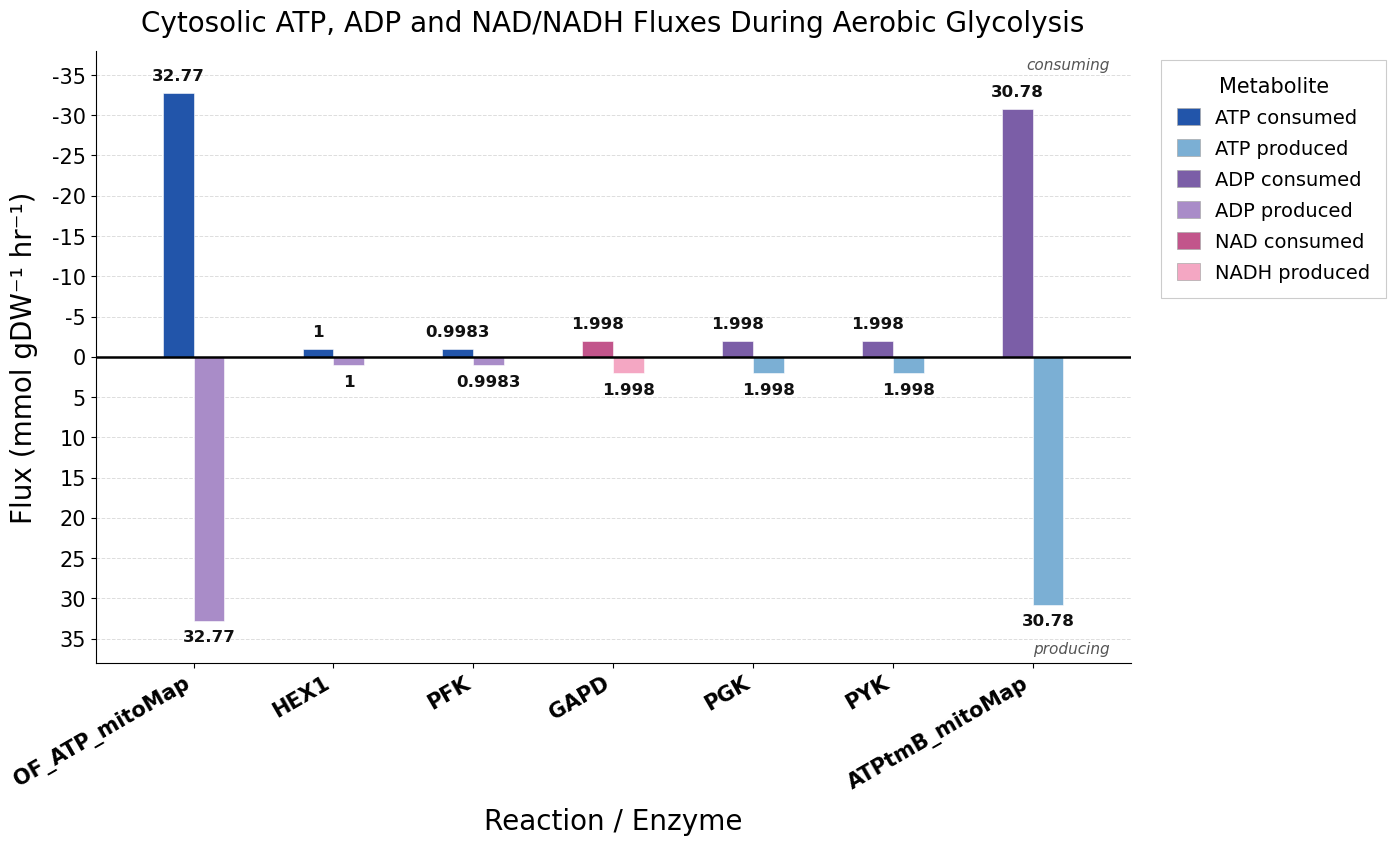

In [34]:

reactions = [
    'OF_ATP_mitoMap', 'HEX1', 'PFK', 'GAPD',
    'PGK', 'PYK', 'ATPtmB_mitoMap',
]

data = [
    ('OF_ATP_mitoMap', 'atp_consumed',  -32.77),
    ('OF_ATP_mitoMap', 'adp_produced',   32.77),
    ('HEX1',           'atp_consumed',   -1.0),
    ('HEX1',           'adp_produced',    1.0),
    ('PFK',            'atp_consumed',   -0.9983),
    ('PFK',            'adp_produced',    0.9983),
    ('GAPD',          'nad_consumed',   -1.998),
    ('GAPD',          'nadh_produced',   1.998),
    ('PGK',            'adp_consumed',   -1.998),
    ('PGK',            'atp_produced',    1.998),
    ('PYK',            'adp_consumed',   -1.998),
    ('PYK',            'atp_produced',    1.998),
    ('ATPtmB_mitoMap', 'adp_consumed',  -30.78),
    ('ATPtmB_mitoMap', 'atp_produced',   30.78),
]

colours = {
    'atp_consumed':  '#2255AA',
    'atp_produced':  '#7BAFD4',
    'adp_produced':  '#A98CC8',
    'adp_consumed':  '#7B5EA7',
    'nad_consumed':  '#C2558B',
    'nadh_produced': '#F4A7C3',
}
legend_labels = {
    'atp_consumed':  'ATP consumed',
    'atp_produced':  'ATP produced',
    'adp_consumed':  'ADP consumed',
    'adp_produced':  'ADP produced',
    'nad_consumed':  'NAD consumed',
    'nadh_produced': 'NADH produced',
}

fig, ax = plt.subplots(figsize=(15, 9))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
fig.subplots_adjust(left=0.09, right=0.78, top=0.88, bottom=0.20)

x_positions = {rxn: i for i, rxn in enumerate(reactions)}
bar_width = 0.22

ax.set_ylim(38, -38)

reaction_bars = defaultdict(list)
for rxn, met_type, flux in data:
    reaction_bars[rxn].append((met_type, flux))

for rxn, bars in reaction_bars.items():
    x_base = x_positions[rxn]
    n = len(bars)
    offsets = np.linspace(-(n-1)*bar_width/2, (n-1)*bar_width/2, n)

    for (met_type, flux), x_off in zip(bars, offsets):
        ax.bar(x_base + x_off, flux,
               width=bar_width,
               color=colours[met_type],
               edgecolor='white', linewidth=0.4, zorder=3)
        gap = 3.0
        fmt = f'{abs(flux):.2f}' if abs(flux) >= 10 else f'{abs(flux):.4g}'

        if flux < 0:           
            y_txt = flux - gap
            va    = 'top'
        else:                  
            y_txt = flux + gap
            va    = 'bottom'

        ax.text(x_base + x_off, y_txt, fmt,
                ha='center', va=va,
                fontsize=12, color='#111111', fontweight='bold',
                zorder=6, clip_on=False)

ax.axhline(0, color='black', linewidth=1.8, zorder=4)
ax.set_xticks(range(len(reactions)))
ax.set_xticklabels(reactions, rotation=30, ha='right',
                   fontsize=15, fontweight='bold')
ax.set_xlim(-0.7, len(reactions) - 0.3)

yticks = np.arange(-35, 36, 5)
ax.set_yticks(yticks)
ax.set_yticklabels([str(int(v)) for v in yticks], fontsize=15)

ax.set_ylabel('Flux (mmol gDW⁻¹ hr⁻¹)', fontsize=20, labelpad=10)
ax.set_xlabel('Reaction / Enzyme', fontsize=20, labelpad=10)
ax.set_title(
    'Cytosolic ATP, ADP and NAD/NADH Fluxes During Aerobic Glycolysis',
    fontsize=20, fontweight='500', pad=14,
)

ax.yaxis.grid(True, color='#DDDDDD', linestyle='--', linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.text(0.98, 0.99,
        'consuming',
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=11, color='#555555', fontstyle='italic')

ax.text(0.98, 0.01,
        'producing',
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=11, color='#555555', fontstyle='italic')

legend_order = [
    'atp_consumed', 'atp_produced',
    'adp_consumed', 'adp_produced',
    'nad_consumed', 'nadh_produced',
]
patches = [
    mpatches.Patch(facecolor=colours[k], edgecolor='#AAAAAA',
                   linewidth=0.5, label=legend_labels[k])
    for k in legend_order
]
legend = ax.legend(
    handles=patches,
    title='Metabolite',
    title_fontsize=15,
    fontsize=14,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    bbox_transform=ax.transAxes,
    frameon=True, framealpha=1.0,
    edgecolor='#CCCCCC',
    fancybox=False,
    borderpad=0.8, labelspacing=0.6,
    handlelength=1.2, handleheight=1.0,
)
legend.get_frame().set_linewidth(0.8)





__________________________________________________________________________________________________________________________________________________

PMF

In [35]:
#proton motive force and mitochondrial carriers
#PMF generation and consumption, and identification of the carriers whose PMF costs explain the ATP synthase output of 28.806 instead of 28 (thesis Equations 4.1–4.3).
#identifying the PMF pseudo-metabolites in the model, which represent the proton motive force across the inner mitochondrial membrane
pmf_mets = [m for m in MitoMammal_model.metabolites
            if "pmf" in m.id.lower() or "pmf" in m.name.lower()]

for m in pmf_mets:
    print(m.id, "|", m.name, "|", m.compartment)


PMF_c | Proton Motive Force | Cytosol
PMF_m | Proton Motive Force | Mitochondrion


In [36]:
#for each reaction involving PMF_c that carries flux, calculate its PMF change (coefficient x flux)
#positive = PMF generated (proton pumping by complexes I, III and IV); negative = PMF consumed (ATP synthase and carriers)

pmf_c = MitoMammal_model.metabolites.get_by_id("PMF_c")

for rxn in pmf_c.reactions:
    flux = solution.fluxes[rxn.id]
    if abs(flux) > 1e-6:
        pmf_change = rxn.metabolites[pmf_c] * flux
        print(f"{rxn.id:20s} flux={flux:8.3f}  PMF_c change={pmf_change:8.3f}")

CV_mitoMap           flux=  28.806  PMF_c change= -77.777
ATPtmB_mitoMap       flux=  30.785  PMF_c change= -25.244
CIII_mitoMap         flux=  11.881  PMF_c change=  47.525
PYRt2m               flux=   1.989  PMF_c change=  -0.358
CIV_mitoMap          flux=   5.941  PMF_c change=  23.762
ASPGLUmB_mitoMap     flux=   1.979  PMF_c change=  -1.979
PIt2mB_mitoMap       flux=  30.785  PMF_c change=  -5.541
CI_mitoMap           flux=   9.913  PMF_c change=  39.611


In [37]:
#search the model for all reactions transporting phosphate between the cytosol (pi_c) and mitochondrion (pi_m)
#to identify the PMF cost of phosphate import for ATP synthesis, completing the cost per ATP (2.7 + 0.82 + 0.18 = 3.7 PMF)
#only PIt2mB_mitoMap (phosphate carrier, 0.18 PMF) carries flux (30.785), matching the ADP/ATP carrier
#this means that only PIt2mB_mitoMap carries flux (30.785), equal to ATPtmB_mitoMap, confirming one Pi imported per ATP exported, so each cytosolic ATP pays both transport costs (0.82 + 0.18 = 1 PMF)

for rxn in MitoMammal_model.reactions:
    if "pi_c" in [m.id for m in rxn.metabolites] and "pi_m" in [m.id for m in rxn.metabolites]:
        print(rxn.id, "|", rxn.name, "|", rxn.reaction, "|", solution.fluxes[rxn.id])
        

PIt2mB_mitoMap | R_PIt2mB_mitoMap Phosphate carrier (PIC) - Symport phosphate and H+ together | 0.18 PMF_c + h_c + pi_c <=> 0.18 PMF_m + h_m + pi_m | 30.784792454175264
MALtm | R_MALtm Dicarboxylate carrier (DIC) - antiport malate for phosphate | mal_L_c + pi_m <=> mal_L_m + pi_c | 4.176282703318608e-18
SUCCt2m | R_SUCCt2m Dicarboxylate carrier (DIC) - antiport succinate for phosphate | pi_m + succ_c <=> pi_c + succ_m | 0.0


In [38]:
#search the model for reactions transporting mitochondrial aspartate (asp_L_m) that also involve PMF, to identify the PMF cost of the malate-aspartate shuttle
#only ASPGLUmB_mitoMap (aspartate-glutamate carrier) found and it consumes 1 PMF per cycle (flux 1.979), an extra transport cost that lowers/moderates the ATP synthase output
for rxn in MitoMammal_model.reactions:
    if "asp_L_m" in [m.id for m in rxn.metabolites] and "PMF_m" in [m.id for m in rxn.metabolites]:
        print(rxn.id, "|", rxn.reaction, "|", solution.fluxes[rxn.id])

ASPGLUmB_mitoMap | PMF_c + asp_L_m + glu_L_c + h_c --> PMF_m + asp_L_c + glu_L_m + h_m | 1.9785080778108204


### Export Section 2 results to Excel

In [40]:
#Section 2 export to excel: glucose oxidation test (pFBA)

#load a fresh copy of the model and apply the same constraints as above, so these results always reflect the glucose oxidation test, whatever cells have been run
test_model = cobra.io.read_sbml_model(model_path)

#record the default bounds before changing anything
test_default_bounds = {r.id: r.bounds for r in test_model.reactions}

#apply the simulation constraints (identical to the cells above)
for rxn in test_model.exchanges:
    rxn.lower_bound = 0
    rxn.upper_bound = 1000
test_model.reactions.get_by_id("EX_glc_D_e").bounds = (-1, -1)
test_model.reactions.get_by_id("EX_o2_e").bounds = (-1000, 1000)
test_model.reactions.get_by_id("GLCt1r").upper_bound = 1000

#run pFBA
test_solution = pfba(test_model)
print("OF_ATP_mitoMap flux:", test_solution.fluxes["OF_ATP_mitoMap"])   #check: 32.773...

#small helper: fluxes for a list of reactions, with names and equations
def flux_table(model, solution, reaction_ids):
    return pd.DataFrame({
        "Reaction ID": reaction_ids,
        "Name": [model.reactions.get_by_id(r).name for r in reaction_ids],
        "Flux": [solution.fluxes[r] for r in reaction_ids],
        "Reaction equation": [model.reactions.get_by_id(r).reaction for r in reaction_ids],
    })

#constraints: simulation info, every reaction whose bounds differ from the default, and the key reactions at test bounds
test_simulation_info = pd.DataFrame({
    "Item": ["Method", "Objective", "Objective flux (OF_ATP_mitoMap)",
             "Sum of absolute fluxes minimised by pFBA (objective_value)"],
    "Value": ["pFBA (cobra.flux_analysis.pfba)",
              str(test_model.objective.expression),
              test_solution.fluxes["OF_ATP_mitoMap"],
              test_solution.objective_value],
})
test_changed_bounds = pd.DataFrame([
    {"Reaction ID": r.id,
     "Default lower bound": test_default_bounds[r.id][0],
     "Default upper bound": test_default_bounds[r.id][1],
     "Test lower bound": r.lower_bound,
     "Test upper bound": r.upper_bound}
    for r in test_model.reactions if r.bounds != test_default_bounds[r.id]
])
test_constraint_reactions = reaction_details(test_model,
    ["EX_glc_D_e", "GLCt1r", "EX_o2_e", "O2t", "ATPtmB_mitoMap"])

#key fluxes and non-zero exchanges
test_key_fluxes = flux_table(test_model, test_solution,
    ["EX_glc_D_e", "GLCt1r", "EX_o2_e", "O2t", "O2tm", "ATPtmB_mitoMap", "OF_ATP_mitoMap"])
test_exchange_ids = [r.id for r in test_model.exchanges
                     if abs(test_solution.fluxes[r.id]) > 1e-6]
test_exchanges = flux_table(test_model, test_solution, test_exchange_ids)

#metabolite summaries
test_summaries = {met_id: metabolite_summary_table(test_model, met_id, test_solution)
                  for met_id in ["biomass_c", "o2_c", "o2_m", "glc_D_c",
                                 "atp_c", "atp_m", "adp_c",
                                 "nad_c", "nad_m", "nadh_c", "nadh_m",
                                 "pyr_c", "pyr_m", "accoa_c", "accoa_m"]}

#PMF accounting
test_pmf_mets = pd.DataFrame([
    {"Metabolite ID": m.id, "Name": m.name, "Compartment": m.compartment}
    for m in test_model.metabolites if "pmf" in m.id.lower() or "pmf" in m.name.lower()
])
test_pmf_c = test_model.metabolites.get_by_id("PMF_c")
test_pmf_accounting = pd.DataFrame([
    {"Reaction ID": rxn.id,
     "Name": rxn.name,
     "Flux": test_solution.fluxes[rxn.id],
     "PMF_c coefficient": rxn.metabolites[test_pmf_c],
     "PMF_c change": rxn.metabolites[test_pmf_c] * test_solution.fluxes[rxn.id]}
    for rxn in test_pmf_c.reactions if abs(test_solution.fluxes[rxn.id]) > 1e-6
])
test_pmf_totals = pd.DataFrame({
    "Item": ["PMF generated (sum of positive changes)",
             "PMF consumed (sum of negative changes)",
             "Net (should be ~0 at steady state)"],
    "Value": [test_pmf_accounting.loc[test_pmf_accounting["PMF_c change"] > 0, "PMF_c change"].sum(),
              test_pmf_accounting.loc[test_pmf_accounting["PMF_c change"] < 0, "PMF_c change"].sum(),
              test_pmf_accounting["PMF_c change"].sum()],
})

#phosphate carriers and the aspartate-glutamate carrier (same searches as the cells above)
test_pi_ids = [r.id for r in test_model.reactions
               if {"pi_c", "pi_m"} <= {m.id for m in r.metabolites}]
test_pi_carriers = flux_table(test_model, test_solution, test_pi_ids)
test_asp_ids = [r.id for r in test_model.reactions
                if {"asp_L_m", "PMF_m"} <= {m.id for m in r.metabolites}]
test_asp_carriers = flux_table(test_model, test_solution, test_asp_ids)

#carriers with PMF costs discussed in the thesis, with full details
test_carriers = reaction_details(test_model,
    ["ATPtmB_mitoMap", "PIt2mB_mitoMap", "ASPGLUmB_mitoMap", "PYRt2m"])
test_carriers.insert(2, "Flux", [test_solution.fluxes[r] for r in test_carriers["Reaction ID"]])

#write one excel workbook with one sheet per topic
section2_file = "Section2_Simulation_Model Constraints_ Glucose_Ox.xlsx"
s = test_summaries

with pd.ExcelWriter(section2_file, engine="openpyxl") as writer:
    write_sheet(writer, "Constraints", "Simulation constraints and objective", [
        ("Simulation", test_simulation_info),
        ("Bounds changed from the default model", test_changed_bounds),
        ("Key reactions at test bounds", test_constraint_reactions),
    ])
    write_sheet(writer, "Key fluxes", "Key fluxes (mol per mol glucose)", [
        ("Uptake, transport, ADP/ATP carrier and objective", test_key_fluxes),
        ("Non-zero exchange fluxes (negative = uptake, positive = secretion)", test_exchanges),
        ("Metabolite summary: biomass_c", s["biomass_c"]),
    ])
    write_sheet(writer, "Oxygen", "Oxygen", [
        ("Metabolite summary: o2_c (cytosol)", s["o2_c"]),
        ("Metabolite summary: o2_m (mitochondrion)", s["o2_m"]),
    ])
    write_sheet(writer, "Glucose", "Glucose", [
        ("Metabolite summary: glc_D_c (cytosol)", s["glc_D_c"]),
    ])
    write_sheet(writer, "ATP and ADP", "ATP and ADP", [
        ("Metabolite summary: atp_c (cytosol)", s["atp_c"]),
        ("Metabolite summary: atp_m (mitochondrion)", s["atp_m"]),
        ("Metabolite summary: adp_c (cytosol)", s["adp_c"]),
    ])
    write_sheet(writer, "NAD and NADH", "NAD+ and NADH", [
        ("Metabolite summary: nad_c (cytosol)", s["nad_c"]),
        ("Metabolite summary: nad_m (mitochondrion)", s["nad_m"]),
        ("Metabolite summary: nadh_c (cytosol)", s["nadh_c"]),
        ("Metabolite summary: nadh_m (mitochondrion)", s["nadh_m"]),
    ])
    write_sheet(writer, "Pyruvate", "Pyruvate", [
        ("Metabolite summary: pyr_c (cytosol)", s["pyr_c"]),
        ("Metabolite summary: pyr_m (mitochondrion)", s["pyr_m"]),
    ])
    write_sheet(writer, "Acetyl-CoA", "Acetyl-CoA", [
        ("Metabolite summary: accoa_c (cytosol)", s["accoa_c"]),
        ("Metabolite summary: accoa_m (mitochondrion)", s["accoa_m"]),
    ])
    write_sheet(writer, "PMF", "Proton motive force (PMF) accounting", [
        ("PMF pseudo-metabolites", test_pmf_mets),
        ("Reactions changing PMF_c", test_pmf_accounting),
        ("PMF totals", test_pmf_totals),
    ])
    write_sheet(writer, "Carriers", "Mitochondrial carriers", [
        ("Carriers with PMF costs (details)", test_carriers),
        ("Reactions transporting phosphate (pi_c <-> pi_m)", test_pi_carriers),
        ("Reactions transporting aspartate with PMF (asp_L_m + PMF_m)", test_asp_carriers),
    ])

print("Saved to:", os.path.abspath(section2_file))

OF_ATP_mitoMap flux: 32.773125787508555
Saved to: c:\Users\cayle\OneDrive\Documents\Master's Reserach\MitoMammal Data\MitoMammal Coding Books\Section2_Simulation_Model Constraints_ Glucose_Ox.xlsx
